##Step 1: Verify the dataset and GPU

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import torch

# Set up device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Existing dataset paths
BASE_DIR = "/content/drive/MyDrive/PCOS_Project"
SPLIT_DIR = os.path.join(BASE_DIR, "SPLIT_DATASET")

# Verify image counts
for split in ["train", "test"]:
    print(f"\n{split.upper()} dataset:")

    for class_name in ["infected", "noninfected"]:
        folder = os.path.join(SPLIT_DIR, split, class_name)

        if not os.path.isdir(folder):
            raise FileNotFoundError(f"Missing folder: {folder}")

        count = sum(
            1 for f in os.listdir(folder)
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp", ".webp")
            )
        )

        print(f"{class_name}: {count} images")

print("\nDataset verification completed.")

Mounted at /content/drive
Device: cuda

TRAIN dataset:
infected: 2520 images
noninfected: 622 images

TEST dataset:
infected: 630 images
noninfected: 156 images

Dataset verification completed.


##Step 2: Create data loaders

In [ ]:
import os
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Dataset paths
BASE_DIR = "/content/drive/MyDrive/PCOS_Project"
SPLIT_DIR = os.path.join(BASE_DIR, "SPLIT_DATASET")

# Configuration
IMAGE_SIZE = 224
BATCH_SIZE = 32

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ImageNet normalization
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Training transformations with augmentation
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(5),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

# Test transformations without random augmentation
test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

# Load existing split
train_dataset = datasets.ImageFolder(
    os.path.join(SPLIT_DIR, "train"),
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    os.path.join(SPLIT_DIR, "test"),
    transform=test_transform
)

# Create loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# Verify
print("\nClass mapping:", train_dataset.class_to_idx)
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

images, labels = next(iter(train_loader))
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Device: cuda

Class mapping: {'infected': 0, 'noninfected': 1}
Training images: 3142
Testing images: 786
Training batches: 99
Testing batches: 25
Batch image shape: torch.Size([32, 3, 224, 224])
Batch label shape: torch.Size([32])


##Step 3: Load pretrained Vision Transformer

In [ ]:
import torch
import torch.nn as nn
from torchvision import models

# Load pretrained Vision Transformer B/16
weights = models.ViT_B_16_Weights.DEFAULT
model = models.vit_b_16(weights=weights)

# Replace classification head for 2 classes
num_features = model.heads.head.in_features
model.heads.head = nn.Linear(num_features, 2)

# Move model to GPU
model = model.to(device)

print("Model: Vision Transformer ViT-B/16")
print("Pretrained weights: ImageNet")
print("Input image size:", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Patch size: 16 x 16")
print("Input features:", num_features)
print("Output classes:", model.heads.head.out_features)
print("Device:", device)
print("Vision Transformer loaded successfully!")

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 177MB/s]


Model: Vision Transformer ViT-B/16
Pretrained weights: ImageNet
Input image size: 224 x 224
Patch size: 16 x 16
Input features: 768
Output classes: 2
Device: cuda
Vision Transformer loaded successfully!


##Step 4: Configure loss function and optimizer

In [ ]:
import torch.nn as nn
import torch.optim as optim

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001
)

# Count trainable parameters
trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Loss function:", criterion)
print("Optimizer: Adam")
print("Learning rate:", 0.0001)
print("Trainable parameters:", f"{trainable_params:,}")
print("ViT training configuration ready!")

Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.0001
Trainable parameters: 85,800,194
ViT training configuration ready!


##Step 5: Train for 5 epochs

In [ ]:
import time
import torch

num_epochs = 5

# Save training history for later plots
train_losses = []
train_accuracies = []

for epoch in range(num_epochs):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0
    start_time = time.time()

    for batch_idx, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        if (batch_idx + 1) % 10 == 0 or (batch_idx + 1) == len(train_loader):
            print(
                f"Epoch [{epoch + 1}/{num_epochs}] "
                f"Batch [{batch_idx + 1}/{len(train_loader)}]"
            )

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    elapsed = (time.time() - start_time) / 60

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Loss: {epoch_loss:.4f} | "
        f"Accuracy: {epoch_accuracy:.2f}% | "
        f"Time: {elapsed:.2f} min"
    )

print("\nViT training completed!")
print("Training loss history:", train_losses)
print("Training accuracy history:", train_accuracies)

Epoch [1/5] Batch [10/99]
Epoch [1/5] Batch [20/99]
Epoch [1/5] Batch [30/99]
Epoch [1/5] Batch [40/99]
Epoch [1/5] Batch [50/99]
Epoch [1/5] Batch [60/99]
Epoch [1/5] Batch [70/99]
Epoch [1/5] Batch [80/99]
Epoch [1/5] Batch [90/99]
Epoch [1/5] Batch [99/99]
Epoch [1/5] Loss: 0.2098 | Accuracy: 92.04% | Time: 9.47 min
Epoch [2/5] Batch [10/99]
Epoch [2/5] Batch [20/99]
Epoch [2/5] Batch [30/99]
Epoch [2/5] Batch [40/99]
Epoch [2/5] Batch [50/99]
Epoch [2/5] Batch [60/99]
Epoch [2/5] Batch [70/99]
Epoch [2/5] Batch [80/99]
Epoch [2/5] Batch [90/99]
Epoch [2/5] Batch [99/99]
Epoch [2/5] Loss: 0.0841 | Accuracy: 97.55% | Time: 1.84 min
Epoch [3/5] Batch [10/99]
Epoch [3/5] Batch [20/99]
Epoch [3/5] Batch [30/99]
Epoch [3/5] Batch [40/99]
Epoch [3/5] Batch [50/99]
Epoch [3/5] Batch [60/99]
Epoch [3/5] Batch [70/99]
Epoch [3/5] Batch [80/99]
Epoch [3/5] Batch [90/99]
Epoch [3/5] Batch [99/99]
Epoch [3/5] Loss: 0.0875 | Accuracy: 96.75% | Time: 1.83 min
Epoch [4/5] Batch [10/99]
Epoch [4/5]

##Step 6: Save the ViT checkpoint

In [ ]:
import os
import torch

SAVE_DIR = "/content/drive/MyDrive/PCOS_Project/model_checkpoints"
os.makedirs(SAVE_DIR, exist_ok=True)

checkpoint_path = os.path.join(
    SAVE_DIR, "vit_b16_baseline.pth"
)

torch.save({
    "model_state_dict": model.state_dict(),
    "class_to_idx": train_dataset.class_to_idx,
    "epochs_trained": 5,
    "image_size": IMAGE_SIZE,
    "train_losses": train_losses,
    "train_accuracies": train_accuracies
}, checkpoint_path)

print("ViT-B/16 checkpoint saved successfully!")
print("Saved to:", checkpoint_path)
print(
    "File size (MB):",
    round(os.path.getsize(checkpoint_path) / (1024 * 1024), 2)
)

ViT-B/16 checkpoint saved successfully!
Saved to: /content/drive/MyDrive/PCOS_Project/model_checkpoints/vit_b16_baseline.pth
File size (MB): 327.36


##Step 7 — Evaluate the ViT-B/16 model

In [ ]:
import torch
import torch.nn as nn
import numpy as np
from torchvision import models
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Recreate the ViT-B/16 architecture without downloading pretrained weights
model_eval = models.vit_b_16(weights=None)
model_eval.heads.head = nn.Linear(
    model_eval.heads.head.in_features, 2
)

# Load the saved checkpoint
checkpoint_path = (
    "/content/drive/MyDrive/PCOS_Project/"
    "model_checkpoints/vit_b16_baseline.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model_eval.load_state_dict(checkpoint["model_state_dict"])
model_eval = model_eval.to(device)
model_eval.eval()

# Evaluate on the test dataset
y_true = []
y_pred = []
y_prob = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model_eval(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = torch.argmax(outputs, dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())
        y_prob.extend(probabilities[:, 1].cpu().numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

# Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
auc = roc_auc_score(y_true, y_prob)

print("ViT-B/16 BASELINE — TEST RESULTS")
print("=" * 45)
print(f"Test samples: {len(y_true)}")
print(f"Test accuracy: {accuracy * 100:.2f}%")
print(f"ROC-AUC (class 1: noninfected): {auc * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["infected", "noninfected"],
    digits=4,
    zero_division=0
))

print("Confusion Matrix:")
print(cm)

ViT-B/16 BASELINE — TEST RESULTS
Test samples: 786
Test accuracy: 96.69%
ROC-AUC (class 1: noninfected): 99.48%

Classification Report:
              precision    recall  f1-score   support

    infected     0.9646    0.9952    0.9797       630
 noninfected     0.9779    0.8526    0.9110       156

    accuracy                         0.9669       786
   macro avg     0.9713    0.9239    0.9453       786
weighted avg     0.9673    0.9669    0.9660       786

Confusion Matrix:
[[627   3]
 [ 23 133]]


##Step 9 — Generate the confusion matrix and ROC curve

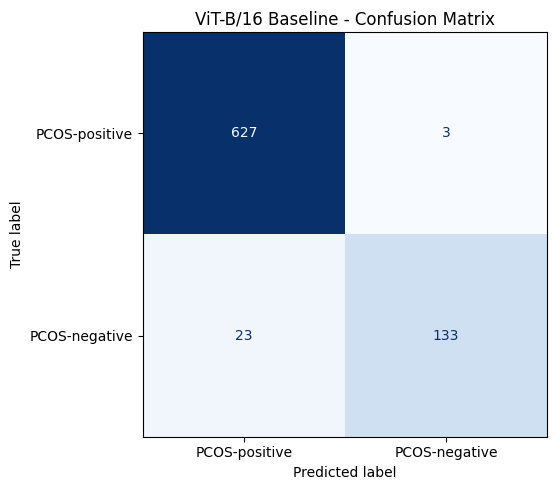

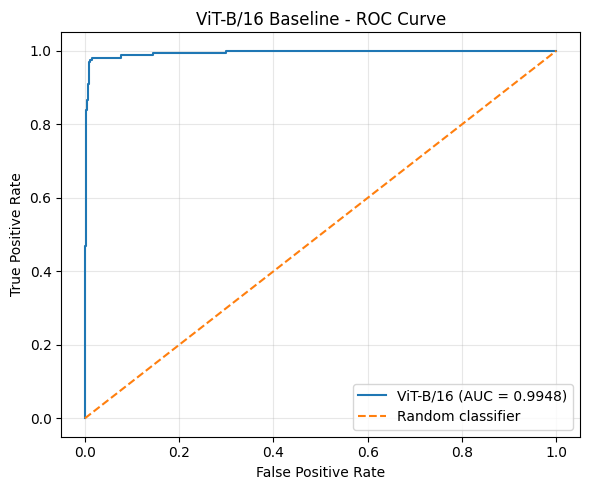

Plots saved successfully:
/content/drive/MyDrive/PCOS_Project/vit_b16_confusion_matrix.png
/content/drive/MyDrive/PCOS_Project/vit_b16_roc_curve.png


In [ ]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, auc

OUTPUT_DIR = "/content/drive/MyDrive/PCOS_Project"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["PCOS-positive", "PCOS-negative"]
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

ax.set_title("ViT-B/16 Baseline - Confusion Matrix")
plt.tight_layout()

cm_path = os.path.join(
    OUTPUT_DIR, "vit_b16_confusion_matrix.png"
)
plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# 2. ROC Curve
fpr, tpr, thresholds = roc_curve(y_true, y_prob, pos_label=1)
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, label=f"ViT-B/16 (AUC = {roc_auc:.4f})")
ax.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ViT-B/16 Baseline - ROC Curve")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.tight_layout()

roc_path = os.path.join(
    OUTPUT_DIR, "vit_b16_roc_curve.png"
)
plt.savefig(roc_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Plots saved successfully:")
print(cm_path)
print(roc_path)